## Virtual Screening Project Notebook
- 1. Data Preparation
- 2. Ligand-based screening
- 3. Structure-based screening
- 4. ML
- 5. Evaluation (ROC+AUC)
- 6. Clustering (?)

1. Imports
2. Data preparation (load actives/inactives, reference-set split, salt removal, ChEMBL IC50 pull)
3. Ligand-based screening
   3.1 Fingerprints (MACCS, Morgan)
   3.2 Similarity scoring (Tanimoto/Dice × MACCS/Morgan)
   3.3 Ligand-based evaluation (enrichment + ROC, full library)
4. Structure-based screening
   4.1 Ligand/receptor prep for docking (subsampling, salts, obabel/meeko → pdbqt)
   4.2 Vina docking + score extraction
   4.3 Smina docking + score extraction
   4.4 Structure-based evaluation (enrichment + ROC, docked subset)
5. Consensus / ML scoring
   5.1 Merge similarity + docking scores into one dataframe
   5.2 Leakage diagnostics (near-duplicate check, scaffold split)
   5.3 Logistic regression
   5.4 Random forest
   5.5 Model comparison (LogReg vs RF)
6. Comparative evaluation (ligand-based vs structure-based vs consensus, one figure)
7. Selected hits table
8. (optional) Single-molecule demo

1. **Import libraries**

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
from rdkit.Chem import (
PandasTools,
Draw,
Descriptors,
MACCSkeys,
rdFingerprintGenerator,
AllChem,
)
from openbabel import pybel

2. **Data preparation (load actives/inactives, reference-set split, salt removal, ChEMBL IC50 pull)**

In [3]:
#creates list of lists
with open("./HMGR-actives.smi") as file_smiles:
    smiles_list = [line.rstrip().split(" ") for line in file_smiles]
#populate df
active_molecule_dataset = pd.DataFrame(data=smiles_list, columns=['Smiles','CHEMBL_ID'])

In [5]:
#creates list of lists
with open("./HMGR-inactives.smi") as file_smiles:
    smiles_list = [line.rstrip().split(" ") for line in file_smiles]
#populate df
inactive_molecule_dataset = pd.DataFrame(data=smiles_list, columns=['Smiles','CHEMBL_ID'])

In [6]:
inactive_molecule_dataset.shape

(8324, 2)

In [7]:
#randomly select 20 actives from the active dataset
reference_index = active_molecule_dataset.sample(n=20, random_state=42).index
reference_dataset = active_molecule_dataset.loc[reference_index]


In [8]:
#save the reference dataset as easy acessible array
reference_dataset.to_csv("./reference_dataset.csv", index=False)

In [11]:
#combine active and inactive datasets
#add column to indicate activity status
active_molecule_dataset['Activity'] = 'Active'
#active_molecule_dataset.drop(reference_index, inplace=True)
inactive_molecule_dataset['Activity'] = 'Inactive'
molecule_dataset = pd.concat([active_molecule_dataset, inactive_molecule_dataset], ignore_index=True)

In [12]:
molecule_dataset.head()
active_molecule_dataset.shape

(131, 3)

3. **Check for duplicates**

In [126]:
if molecule_dataset.duplicated().any():
    print("Warning: Duplicate entries found in the dataset.")
else:
    print("No duplicate entries found in the dataset.")

No duplicate entries found in the dataset.


4. **Remove salts**

In [127]:

from rdkit.Chem.SaltRemover import SaltRemover
for index, row in molecule_dataset.iterrows():
    smiles = row['Smiles']
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        remover = SaltRemover()
        mol_no_salts = remover.StripMol(mol)
        smiles_no_salts = Chem.MolToSmiles(mol_no_salts)
        molecule_dataset.at[index, 'Smiles'] = smiles_no_salts

5. **Pull activity data from CHEMBL database** | *for target: CHEMBL402*

In [128]:
from chembl_webresource_client.new_client import new_client
import numpy as np
def get_ic50_by_chembl_id(molecule_chembl_id, target_chembl_id):
    try:
        activity = new_client.activity
        res = activity.filter(
        molecule_chembl_id=molecule_chembl_id,
        target_chembl_id=target_chembl_id,
        standard_type='IC50'
        )
        pchembl_values = []
        for record in res:
            val = record.get('pchembl_value')
        # Ensure it exists and isn't empty
            if val is not None and str(val).strip() != '':
                pchembl_values.append(float(val))
            
        # If multiple values exist across different papers, take the average
        if pchembl_values:
            return np.mean(pchembl_values)
    except Exception as e:
        print(f"Error fetching IC50 for {molecule_chembl_id}: {e}")

    return np.nan  
    
molecule_dataset['IC50'] = np.nan

    
for index, row in molecule_dataset.iterrows():
    molecule_id = row['CHEMBL_ID']
    target_id = 'CHEMBL402'
    ic50 = get_ic50_by_chembl_id(molecule_id, target_id)
    molecule_dataset.at[index, 'IC50'] = ic50
molecule_dataset.head()

KeyboardInterrupt: 

In [13]:
#save the result as easy acessible array
molecule_dataset.to_csv("./molecule_dataset.csv", index=False)

In [4]:
#open the file and read it into a DataFrame
molecule_dataset = pd.read_csv("./molecule_dataset.csv")
reference_dataset = pd.read_csv('./reference_dataset.csv')

In [16]:
actives_names_list = active_molecule_dataset['CHEMBL_ID']
print(list(actives_names_list))
print(len(actives_names_list))

['CHEMBL1496', 'CHEMBL1487', 'CHEMBL54440', 'CHEMBL1144', 'CHEMBL169046', 'CHEMBL1477', 'CHEMBL1161644', 'CHEMBL2220442', 'CHEMBL2367472', 'CHEMBL1163804', 'CHEMBL64962', 'CHEMBL99838', 'CHEMBL100165', 'CHEMBL101497', 'CHEMBL102168', 'CHEMBL151437', 'CHEMBL159951', 'CHEMBL160102', 'CHEMBL161829', 'CHEMBL162642', 'CHEMBL163277', 'CHEMBL175236', 'CHEMBL177545', 'CHEMBL228528', 'CHEMBL228583', 'CHEMBL228667', 'CHEMBL228954', 'CHEMBL249273', 'CHEMBL249724', 'CHEMBL249884', 'CHEMBL249906', 'CHEMBL250090', 'CHEMBL250317', 'CHEMBL250500', 'CHEMBL250707', 'CHEMBL250749', 'CHEMBL250953', 'CHEMBL251499', 'CHEMBL303515', 'CHEMBL321768', 'CHEMBL329307', 'CHEMBL333443', 'CHEMBL333760', 'CHEMBL345375', 'CHEMBL348798', 'CHEMBL387514', 'CHEMBL389002', 'CHEMBL389216', 'CHEMBL389442', 'CHEMBL389443', 'CHEMBL391002', 'CHEMBL394937', 'CHEMBL398239', 'CHEMBL398240', 'CHEMBL398551', 'CHEMBL399315', 'CHEMBL399360', 'CHEMBL399771', 'CHEMBL399773', 'CHEMBL400560', 'CHEMBL400747', 'CHEMBL400874', 'CHEMBL400973'

6. **Compute fingerprints for every compound**

In [5]:
PandasTools.AddMoleculeColumnToFrame(reference_dataset, smilesCol="Smiles")
PandasTools.AddMoleculeColumnToFrame(molecule_dataset, smilesCol="Smiles")

In [6]:
#Calculate the fingerprints for the compounds of the df
#Article uses GetMorganFingerprintAsBitVect`, 2048 bits, radius 2, and MACCS (167 bits) as second descriptor to compare
reference_dataset["maccs"] = reference_dataset.ROMol.apply(MACCSkeys.GenMACCSKeys)
reference_dataset["morgan"] = reference_dataset["ROMol"].apply(lambda mol:AllChem.GetMorganFingerprintAsBitVect
                                                 (mol, 2, nBits=2048, useChirality=False))


molecule_dataset["maccs"] = molecule_dataset.ROMol.apply(MACCSkeys.GenMACCSKeys)
molecule_dataset["morgan"] = molecule_dataset["ROMol"].apply(lambda mol:AllChem.GetMorganFingerprintAsBitVect
                                                 (mol, 2, nBits=2048, useChirality=False))

molecule_dataset.head()

,Smiles,CHEMBL_ID,Activity,IC50,ROMol,maccs,morgan
0,CC(C)c1nc(N(C)S(C)(=O)=O)nc(-c2ccc(F)cc2)c1/C=...,CHEMBL1496,Active,8.3700,<rdkit.Chem.rdchem.Mol object at 0x7a5131806c70>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F...,CHEMBL1487,Active,8.4225,<rdkit.Chem.rdchem.Mol object at 0x7a5131806ce0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CC[C@H](C)C(=O)O[C@H]1CCC=C2C=C[C@H](C)[C@H](C...,CHEMBL54440,Active,7.4375,<rdkit.Chem.rdchem.Mol object at 0x7a5131806d50>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
3,CC[C@H](C)C(=O)O[C@H]1C[C@H](O)C=C2C=C[C@H](C)...,CHEMBL1144,Active,7.3900,<rdkit.Chem.rdchem.Mol object at 0x7a5131806dc0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,C[C@H](CCCC(C)(C)O)[C@H]1CC[C@H]2[C@@H]3CC=C4C...,CHEMBL169046,Active,6.5200,<rdkit.Chem.rdchem.Mol object at 0x7a5131806e30>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, ..."


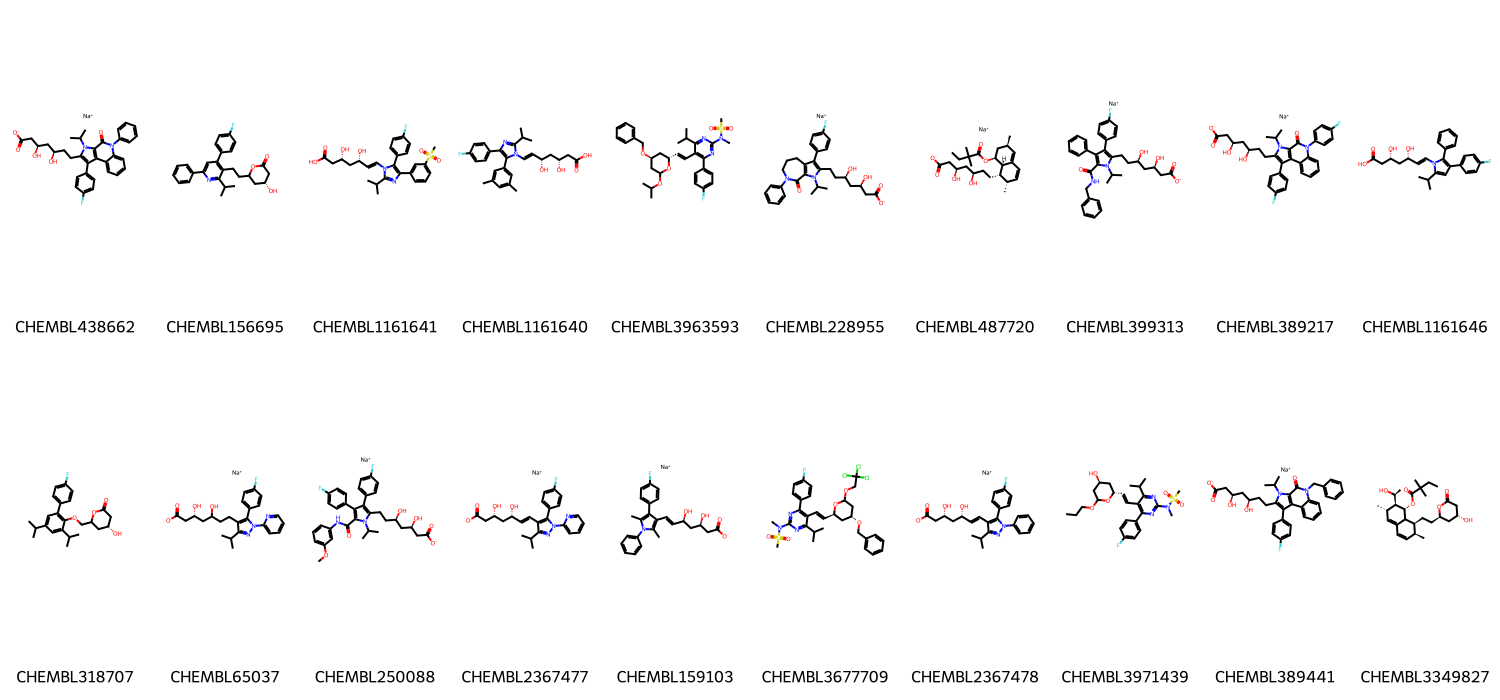

In [109]:
reference_dataset.head(2)
Draw.MolsToGridImage(
reference_dataset["ROMol"].to_list(),
molsPerRow=10,
subImgSize=(150, 350),
legends=reference_dataset["CHEMBL_ID"].to_list())


**MACCS fingerprints**

In [7]:
reference_fps = reference_dataset["maccs"].tolist()
reference_ids = reference_dataset["CHEMBL_ID"].tolist()

candidate_fps = molecule_dataset["maccs"].tolist()  # actives + inactives together
candidate_ids = molecule_dataset["CHEMBL_ID"].tolist()

sim_data = {}
for ref_id, ref_fp in zip(reference_ids, reference_fps):
    sim_data[ref_id] = DataStructs.BulkTanimotoSimilarity(ref_fp, candidate_fps)
    
sim_matrix = pd.DataFrame(sim_data, index=candidate_ids)   # N x 151
sim_matrix["max_sim"] = sim_matrix.max(axis=1)


In [8]:
#add similarity values to the molecule dataset
molecule_dataset["tanimoto_maccs_similarity"] = sim_matrix.max(axis=1).values

In [9]:
sim_data = {}
for ref_id, ref_fp in zip(reference_ids, reference_fps):
    sim_data[ref_id] = DataStructs.BulkDiceSimilarity(ref_fp, candidate_fps)

sim_matrix = pd.DataFrame(sim_data, index=candidate_ids)   # N x 151
sim_matrix["max_sim"] = sim_matrix.max(axis=1)


In [10]:
#add similarity values to the molecule dataset
molecule_dataset["dice_maccs_similarity"] = sim_matrix.max(axis=1).values

In [11]:
sim_matrix.to_csv("./Tanimoto_MACCS.csv")

**Morgan fingerprints**

In [12]:
reference_fps = reference_dataset["morgan"].tolist()
candidate_fps = molecule_dataset["morgan"].tolist()

sim_data = {}
for ref_id, ref_fp in zip(reference_ids, reference_fps):
    sim_data[ref_id] = DataStructs.BulkTanimotoSimilarity(ref_fp, candidate_fps)

sim_matrix_morgan = pd.DataFrame(sim_data, index=candidate_ids)
molecule_dataset["tanimoto_morgan_similarity"] = sim_matrix_morgan.max(axis=1).values
sim_matrix_morgan["max_sim"] = sim_matrix_morgan.max(axis=1)
sim_matrix_morgan.to_csv("./Tanimoto_Morgan.csv")

In [13]:
reference_fps = reference_dataset["morgan"].tolist()
candidate_fps = molecule_dataset["morgan"].tolist()

sim_data = {}
for ref_id, ref_fp in zip(reference_ids, reference_fps):
    sim_data[ref_id] = DataStructs.BulkDiceSimilarity(ref_fp, candidate_fps)

sim_matrix_morgan = pd.DataFrame(sim_data, index=candidate_ids)
molecule_dataset["dice_morgan_similarity"] = sim_matrix_morgan.max(axis=1).values
sim_matrix_morgan["max_sim"] = sim_matrix_morgan.max(axis=1)
#sim_matrix_morgan.to_csv("./Tanimoto_Morgan.csv")

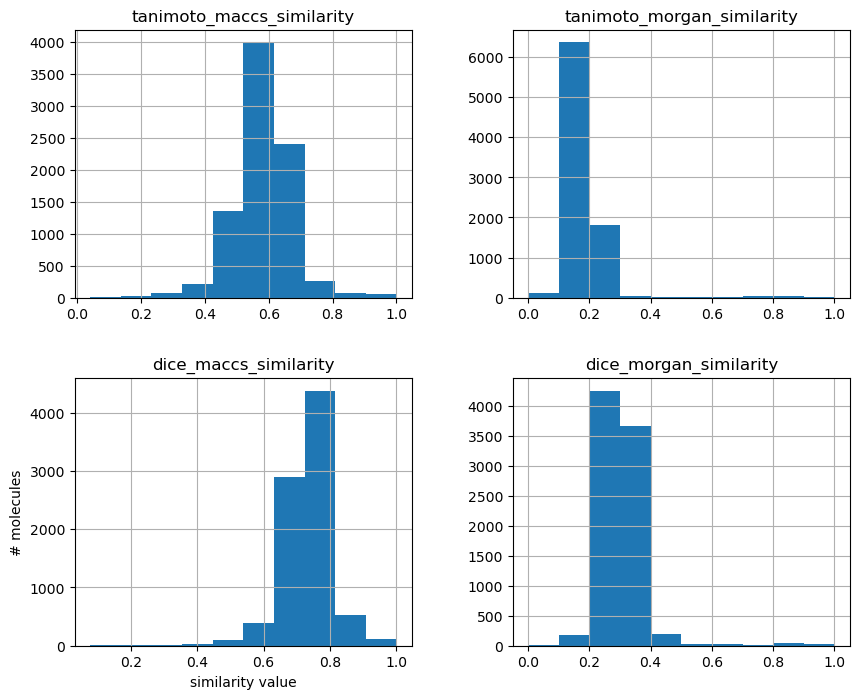

In [26]:
fig, axes = plt.subplots(figsize=(10, 8), nrows=2, ncols=2)
molecule_dataset.hist(["tanimoto_maccs_similarity"], ax=axes[0, 0])
molecule_dataset.hist(["tanimoto_morgan_similarity"], ax=axes[0, 1])
molecule_dataset.hist(["dice_maccs_similarity"], ax=axes[1, 0])
molecule_dataset.hist(["dice_morgan_similarity"], ax=axes[1, 1])
axes[1, 0].set_xlabel("similarity value")
axes[1, 0].set_ylabel("# molecules")
fig;

**Visualize most similar molecules**

In [14]:
molecule_dataset.sort_values(["tanimoto_maccs_similarity"], ascending=False).head(3)

,Smiles,CHEMBL_ID,Activity,IC50,ROMol,maccs,morgan,tanimoto_maccs_similarity,dice_maccs_similarity,tanimoto_morgan_similarity,dice_morgan_similarity
6,CC(C)c1cc(-c2ccc(F)cc2)c(-c2ccc(F)cc2)n1/C=C/[...,CHEMBL1161644,Active,8.11,<rdkit.Chem.rdchem.Mol object at 0x7a5131806f10>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1.0,0.941176,0.969697
74,Cc1cc(-c2c(-c3ccc(F)cc3)nc(C(C)C)n2/C=C/[C@@H]...,CHEMBL1161650,Active,8.12,<rdkit.Chem.rdchem.Mol object at 0x7a51316b0d60>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1.0,0.852459,0.920354
73,CC(C)c1cc(-c2ccccc2)c(-c2ccc(F)cc2)n1/C=C/[C@@...,CHEMBL1161649,Active,8.06,<rdkit.Chem.rdchem.Mol object at 0x7a51316b0cf0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1.0,1.000000,1.000000


In [117]:
molecule_dataset.sort_values(["tanimoto_morgan_similarity"], ascending=False).head(3)

,Smiles,CHEMBL_ID,Activity,IC50,ROMol,maccs,morgan,tanimoto_maccs_similarity,dice_maccs_similarity,tanimoto_morgan_similarity,dice_morgan_similarity
73,CC(C)c1cc(-c2ccccc2)c(-c2ccc(F)cc2)n1/C=C/[C@@...,CHEMBL1161649,Active,8.06,<rdkit.Chem.rdchem.Mol object at 0x7d5628fb40b0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000,1.000000,1.000000,1.000000
49,CC(C)n1c(CC[C@@H](O)C[C@@H](O)CC(=O)[O-])c(-c2...,CHEMBL389443,Active,8.33,<rdkit.Chem.rdchem.Mol object at 0x7d5628faf5a0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.957143,0.978102,0.941176,0.969697
6,CC(C)c1cc(-c2ccc(F)cc2)c(-c2ccc(F)cc2)n1/C=C/[...,CHEMBL1161644,Active,8.11,<rdkit.Chem.rdchem.Mol object at 0x7d5629791cb0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000,1.000000,0.941176,0.969697


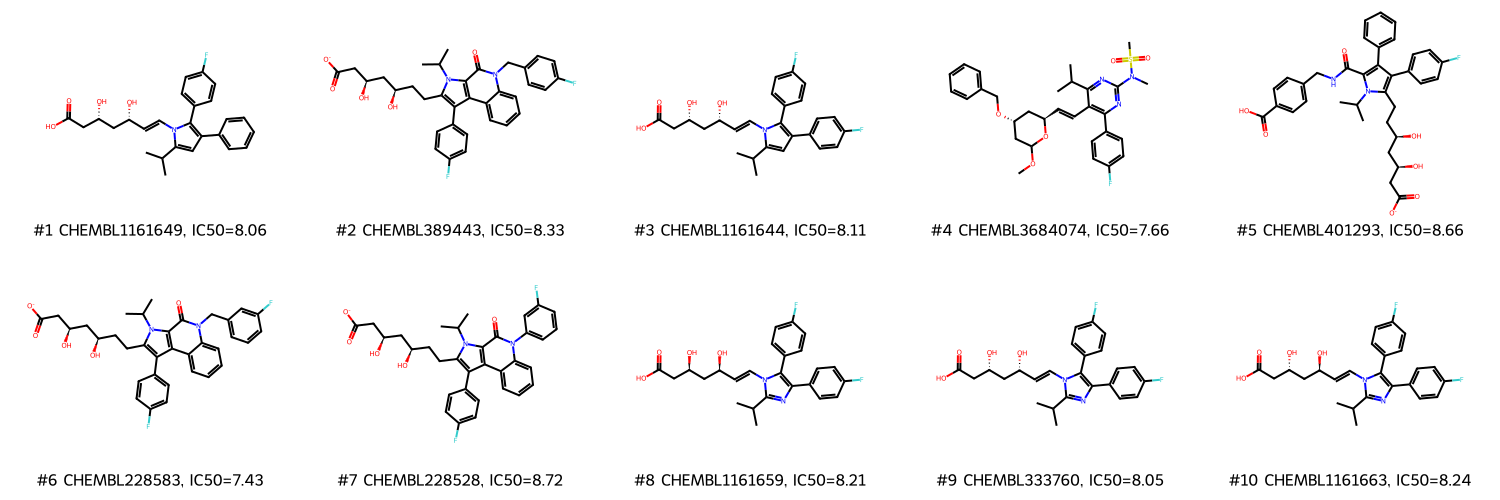

In [15]:
#Show the query and its most similar molecules alongside the molecules’ bioactivities.

top_n_molecules = 10
top_molecules = molecule_dataset.sort_values(["tanimoto_morgan_similarity"], ascending=False).reset_index()
top_molecules = top_molecules[:top_n_molecules]
legends = [
    f"#{index+1} {molecule['CHEMBL_ID']}, IC50={molecule['IC50']:.2f}"
    for index, molecule in top_molecules.iterrows()
]
Chem.Draw.MolsToGridImage(
    mols= top_molecules["ROMol"].tolist(),
    legends=(legends),
    molsPerRow=5,
    subImgSize=(300, 250),
)

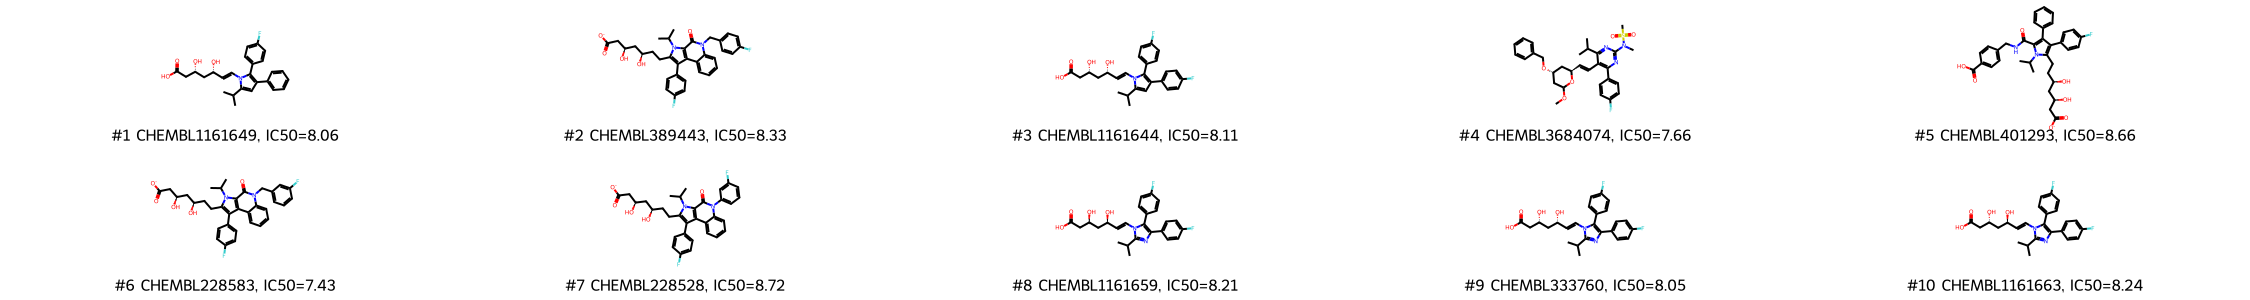

In [16]:
#Show the query and its most similar molecules alongside the molecules’ bioactivities.

top_n_molecules = 10
top_molecules = molecule_dataset.sort_values(["tanimoto_morgan_similarity"], ascending=False).reset_index()
top_molecules = top_molecules[:top_n_molecules]
legends = [
    f"#{index+1} {molecule['CHEMBL_ID']}, IC50={molecule['IC50']:.2f}"
    for index, molecule in top_molecules.iterrows()
]
Chem.Draw.MolsToGridImage(
    mols= top_molecules["ROMol"].tolist(),
    legends=(legends),
    molsPerRow=5,
    subImgSize=(450, 150),
)

9. **Evaluate (ROC, EF)**

**Build enrichment plots**
- the ratio of top-ranked molecules (x-axis) from the whole dataset vs.

- the ratio of active molecules (y-axis) from the whole dataset.



In [17]:
def get_enrichment_data(molecules, similarity_measure, activity_column="Activity"):
    """
    Calculates x and y values for enrichment plot:
        x - % ranked dataset
        y - % true actives identified

    Parameters
    ----------
    molecules : pandas.DataFrame
        Molecules with similarity values to a query molecule.
    similarity_measure : str
        Column name which will be used to sort the DataFrame．
    activity_column : str, optional
        Column name for the activity values.
    Returns
    -------
    pandas.DataFrame
        Enrichment data: Percentage of ranked dataset by similarity vs. percentage of identified true actives.
    """

    # Get number of molecules in data set
    molecules_all = len(molecules)

    # Get number of active molecules in data set
    actives_all = sum(molecules[activity_column] == 'Active')

    # Initialize a list that will hold the counter for actives and molecules while iterating through our dataset
    actives_counter_list = []

    # Initialize counter for actives
    actives_counter = 0

    # Note: Data must be ranked for enrichment plots:
    # Sort molecules by selected similarity measure
    molecules.sort_values([similarity_measure], ascending=False, inplace=True)

    # Iterate over the ranked dataset and check each molecule if active (by checking bioactivity)
    for value in molecules[activity_column]:
        if value == "Active":
            actives_counter += 1
        actives_counter_list.append(actives_counter)

    # Transform number of molecules into % ranked dataset
    molecules_percentage_list = [i / molecules_all for i in range(1, molecules_all + 1)]

    # Transform number of actives into % true actives identified
    actives_percentage_list = [i / actives_all for i in actives_counter_list]

    # Generate DataFrame with x and y values as well as label
    enrichment = pd.DataFrame(
        {
            "% ranked dataset": molecules_percentage_list,
            "% true actives identified": actives_percentage_list,
        }
    )

    return enrichment

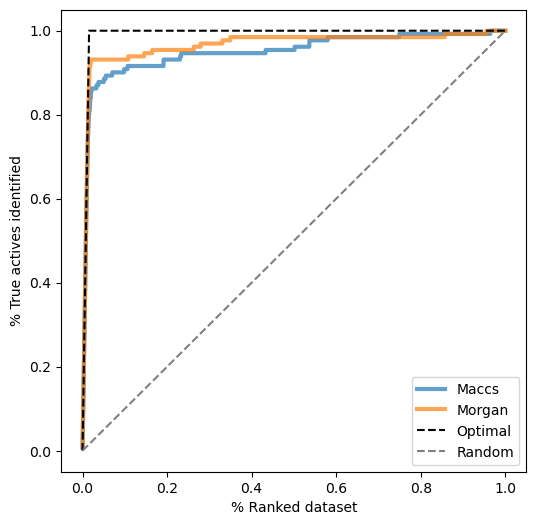

In [18]:
enrichment_data = {"Maccs":get_enrichment_data(molecule_dataset, "tanimoto_maccs_similarity", "Activity"),
                   "Morgan":get_enrichment_data(molecule_dataset, "tanimoto_morgan_similarity", "Activity"),
                   }

fig, ax = plt.subplots(figsize=(6, 6))
for label, enrichment in enrichment_data.items():
    enrichment.plot(ax=ax, x="% ranked dataset", y="% true actives identified",
                     label=label, alpha=0.7, linewidth=3)

ratio_actives = sum(molecule_dataset["Activity"] == "Active") / len(molecule_dataset)
ax.plot([0, ratio_actives, 1], [0, 1, 1], label="Optimal", color="black", linestyle="--")
ax.plot([0, 1], [0, 1], label="Random", color="grey", linestyle="--")
ax.set_xlabel("% Ranked dataset"); ax.set_ylabel("% True actives identified")
ax.legend()
plt.show()

**Calculate enrichment factors**

In [19]:
def calculate_enrichment_factor(enrichment, ranked_dataset_percentage_cutoff):
    """
    Get the experimental enrichment factor for a given percentage of the ranked dataset.

    Parameters
    ----------
    enrichment : pd.DataFrame
        Enrichment data: Percentage of ranked dataset by similarity vs. percentage of
        identified true actives.
    ranked_dataset_percentage_cutoff : float or int
        Percentage of ranked dataset to be included in enrichment factor calculation.

    Returns
    -------
    float
        Experimental enrichment factor.
    """

    # Keep only molecules that meet the cutoff
    enrichment = enrichment[
        enrichment["% ranked dataset"] <= ranked_dataset_percentage_cutoff / 100
    ]
    # Get highest percentage of actives and the corresponding percentage of actives
    highest_enrichment = enrichment.iloc[-1]
    enrichment_factor = round(100 * float(highest_enrichment["% true actives identified"]), 1)
    return enrichment_factor

In [20]:
def calculate_enrichment_factor_random(ranked_dataset_percentage_cutoff):
    """
    Get the random enrichment factor for a given percentage of the ranked dataset.

    Parameters
    ----------
    ranked_dataset_percentage_cutoff : float or int
        Percentage of ranked dataset to be included in enrichment factor calculation.

    Returns
    -------
    float
        Random enrichment factor.
    """

    enrichment_factor_random = round(float(ranked_dataset_percentage_cutoff), 1)
    return enrichment_factor_random

In [21]:
def calculate_enrichment_factor_optimal(molecules, ranked_dataset_percentage_cutoff):
    """
    Get the optimal random enrichment factor for a given percentage of the ranked dataset.

    Parameters
    ----------
    molecules : pandas.DataFrame
        the DataFrame with all the molecules and pIC50.
    ranked_dataset_percentage_cutoff : float or int
        Percentage of ranked dataset to be included in enrichment factor calculation.
    activity_cutoff: float
        pIC50 cutoff value used to discriminate active and inactive molecules

    Returns
    -------
    float
        Optimal enrichment factor.
    """

    ratio = sum(molecules["Activity"] == "Active") / len(molecules) * 100
    if ranked_dataset_percentage_cutoff <= ratio:
        enrichment_factor_optimal = round(100 / ratio * ranked_dataset_percentage_cutoff, 1)
    else:
        enrichment_factor_optimal = 100.0
    return enrichment_factor_optimal

In [22]:
ranked_dataset_percentage_cutoff = 5
for similarity_measure, enrichment in enrichment_data.items():
    enrichment_factor = calculate_enrichment_factor(enrichment, ranked_dataset_percentage_cutoff)
    print(
        f"Experimental EF for {ranked_dataset_percentage_cutoff}% of ranked dataset ({similarity_measure}): {enrichment_factor}%"
    )
enrichment_factor_random = calculate_enrichment_factor_random(ranked_dataset_percentage_cutoff)
print(
    f"Random EF for {ranked_dataset_percentage_cutoff}% of ranked dataset: {enrichment_factor_random}%"
)
enrichment_factor_optimal = calculate_enrichment_factor_optimal(
    molecule_dataset, ranked_dataset_percentage_cutoff
)
print(
    f"Optimal EF for {ranked_dataset_percentage_cutoff}% of ranked dataset: {enrichment_factor_optimal}%"
)

Experimental EF for 5% of ranked dataset (Maccs): 87.8%
Experimental EF for 5% of ranked dataset (Morgan): 93.1%
Random EF for 5% of ranked dataset: 5.0%
Optimal EF for 5% of ranked dataset: 100.0%


### Part 2. Structure-based virtual screening (Docking via Vina)

**1. Prepare the ligands**
- Randomly select the molecules for docking (151 out of 8k)
- Add selected molecules to file with active molecules
- Remove salts from SMILES file
- Translate SMILES data to 3D conformation data (pdbqt format) using Openbabel

**1.1. Select Smiles of inactive molecules for docking**

In [38]:
smiles_list = []
with open("./HMGR-inactives.smi") as file_smiles:
    for line in file_smiles:
            smiles_list += line.rstrip().split(" ")
prefixes = ('CHEMBL','DECOY')
clean_smiles_list = [x for x in smiles_list if not x.startswith(prefixes)]
len(clean_smiles_list)

import random
sampled_inactives = random.sample(clean_smiles_list,151)

with open("./HMGR-inactives-docking.smi", "w") as docking_smiles:
    for smile in sampled_inactives:
            docking_smiles.write(str(smile)+"\n")

**1.2. Remove the salts**

In [ ]:

from rdkit.Chem.SaltRemover import SaltRemover
with open('./ligands.smi', 'r') as f:
   for line in f:
       smiles = line.strip()
       mol_name = line.split()[1]
       mol = Chem.MolFromSmiles(smiles)
       if mol is not None:
           remover = SaltRemover()
           mol_no_salts = remover.StripMol(mol)
           smiles_no_salts = Chem.MolToSmiles(mol_no_salts)
           with open('./ligands_no_salts.smi', 'a') as out_f:
               out_f.write(smiles_no_salts + ' ' + mol_name + '\n')


**1.3. Use bash script to get pdbqt info from SMILES**

In [ ]:
mkdir -p ligands_pdbqt
OBABEL="$(conda info --base)/envs/bioinfo/bin/obabel"

# 1. Convert every molecule in your combined .smi to a separate pdbqt
while read -r smiles id; do
    "$OBABEL" -:"$smiles" -O "ligands_pdbqt/${id}.pdbqt" --gen3d -p 7.4 --partialcharge gasteiger 2>>errors.log
done < ligands_no_salts.smi

**2. Prepare the receptor file**

In [ ]:
from openbabel import openbabel

obConversion = openbabel.OBConversion()
obConversion.SetInAndOutFormats("mol2", "pdbqt")

mol = openbabel.OBMol()
obConversion.ReadFile(mol, "./HMGR-test-protein-OTS.mol2") 
mol.AddHydrogens()

# print(mol.NumAtoms())
# print(mol.NumBonds())
# print(mol.NumResidues())

obConversion.WriteFile(mol, './HMGR-test-protein-OTS.pdbqt')

**3. Select the best docking pose**

In [ ]:
import re, glob
records = []
for log in glob.glob("docked/*.log"):
    text = open(log).read()
    m = re.search(r"^\s*1\s+(-?\d+\.\d+)", text, re.M)  # first (best) pose row
    if m:
        records.append({"CHEMBL_ID": log.split("/")[-1].replace(".log",""),
                         "vina_score": float(m.group(1))})
docking_df = pd.DataFrame(records)

**4. Evaluate docking**

In [39]:
with open("./docked/enrichissement.dat", "r") as f_in, open("./docked/enrichissement_clean.csv", "w") as f_out:
    for line in f_in:
        num = line.split()[0]
        prct = line.split()[1]
        f_out.write(f"{num},{prct}\n")
#Ce fichier contient dans la 1ère colonne le % de la banque, tandis que dans la 2ème colonne, on a le % d’actifs.

with open("./smina_results/enrichissement_smina.dat", "r") as f_in, open("./smina_results/enrichissement_smina_clean.csv", "w") as f_out:
    for line in f_in:
        num = line.split()[0]
        prct = line.split()[1]
        f_out.write(f"{num},{prct}\n")
#Ce fichier contient dans la 1ère colonne le % de la banque, tandis que dans la 2ème colonne, on a le % d’actifs.

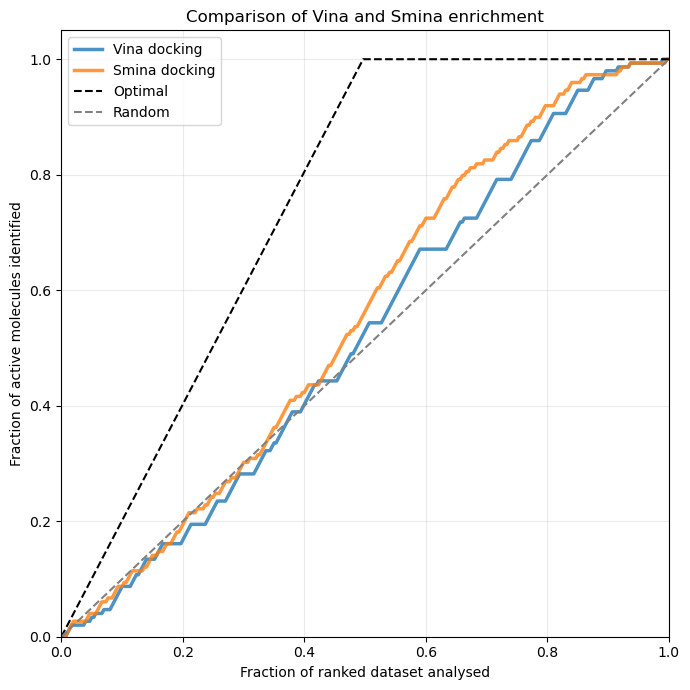

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# The CSV files produced from enrichissement.dat have no header
vina = pd.read_csv(
    "./docked/enrichissement_clean.csv",
    header=None,
    names=["fraction_tested", "actives_identified_percent"],
)

smina = pd.read_csv(
    "./smina_results/enrichissement_smina_clean.csv",
    header=None,
    names=["fraction_tested", "actives_identified_percent"],
)

# Convert percentage of identified actives from 0–100 to 0–1
vina["actives_identified"] = vina["actives_identified_percent"] / 100
smina["actives_identified"] = smina["actives_identified_percent"] / 100

enrichment_data = {
    "Vina": vina,
    "Smina": smina,
}

ratio_actives = 149/300  

fig, ax = plt.subplots(figsize=(7, 7))

for label, enrichment in enrichment_data.items():
    # Add the origin so that both curves start at (0, 0)
    x = [0] + enrichment["fraction_tested"].tolist()
    y = [0] + enrichment["actives_identified"].tolist()

    ax.plot(
        x,
        y,
        linewidth=2.5,
        alpha=0.8,
        label=f"{label} docking",
    )

# Optimal enrichment curve:
# all actives are found before any inactive molecules
ax.plot(
    [0, ratio_actives, 1],
    [0, 1, 1],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Optimal",
)

# Random-ranking curve
ax.plot(
    [0, 1],
    [0, 1],
    color="grey",
    linestyle="--",
    linewidth=1.5,
    label="Random",
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Fraction of ranked dataset analysed")
ax.set_ylabel("Fraction of active molecules identified")
ax.set_title("Comparison of Vina and Smina enrichment")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [43]:
#extract the enrichment factor at 5% of the ranked dataset for both Vina and Smina
def calculate_enrichment_factor(enrichment, ranked_dataset_percentage_cutoff, ratio_actives):
    """
    Get the experimental enrichment factor for a given percentage of the ranked dataset.

    Parameters
    ----------
    enrichment : pd.DataFrame
        Enrichment data: Percentage of ranked dataset by similarity vs. percentage of
        identified true actives.
    ranked_dataset_percentage_cutoff : float or int
        Percentage of ranked dataset to be included in enrichment factor calculation.

    Returns
    -------
    float
        Experimental enrichment factor.
    """
    # Keep only molecules that meet the cutoff
    enrichment = enrichment[
        enrichment["fraction_tested"] <= ranked_dataset_percentage_cutoff / 100
    ]
    # Get highest percentage of actives and the corresponding percentage of actives
    highest_enrichment = enrichment.iloc[-1]
    enrichment_factor = round(100 * float(highest_enrichment["actives_identified"]), 1)

    enrichment_factor_random = round(float(ranked_dataset_percentage_cutoff), 1)

    if ranked_dataset_percentage_cutoff <= ratio_actives:
        enrichment_factor_optimal = round(100 / ratio_actives * ranked_dataset_percentage_cutoff, 1)
    else:
        enrichment_factor_optimal = 100.0

    return enrichment_factor, enrichment_factor_optimal, enrichment_factor_random
    

ranked_dataset_percentage_cutoff = 5

print(f"Experimental, Optimal and Random EF for {ranked_dataset_percentage_cutoff}% of ranked dataset (Vina): {calculate_enrichment_factor(vina,5, ratio_actives)}%")
print(f"Experimental, Optimal and Random EF for {ranked_dataset_percentage_cutoff}% of ranked dataset (Smina): {calculate_enrichment_factor(smina,5,ratio_actives)}%")



Experimental, Optimal and Random EF for 5% of ranked dataset (Vina): (3.4, 100.0, 5.0)%
Experimental, Optimal and Random EF for 5% of ranked dataset (Smina): (4.0, 100.0, 5.0)%


In [44]:
#combine active and inactive datasets
#add column to indicate activity status
active_molecule_dataset['Activity'] = 'Active'
#active_molecule_dataset.drop(reference_index, inplace=True)
inactive_molecule_dataset['Activity'] = 'Inactive'
molecule_dataset = pd.concat([active_molecule_dataset, inactive_molecule_dataset], ignore_index=True)

In [45]:
#exctract the docking scores and activity data and add it to the molecule dataset
vina_scores = pd.read_csv("./docked/energy_data.dat",header=0, names=["vina_score", "CHEMBL_ID"], delimiter="\t")
smina_scores = pd.read_csv("./smina_results/energy_data_smina.dat", header=0, names=["smina_score", "CHEMBL_ID"], delimiter="\t")

for df in (molecule_dataset, vina_scores):
    df["CHEMBL_ID"] = (
        df["CHEMBL_ID"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.(pdbqt|log)$", "", regex=True)
        .str.replace(r"_out$", "", regex=True)
    )


for df in (molecule_dataset, smina_scores):
    df["CHEMBL_ID"] = (
        df["CHEMBL_ID"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.(pdbqt|log)$", "", regex=True)
        .str.replace(r"_out$", "", regex=True)
    )

molecule_dataset = molecule_dataset.merge(
    vina_scores[["CHEMBL_ID", "vina_score"]],
    on="CHEMBL_ID",
    how="left",
    validate="one_to_one",
)

molecule_dataset = molecule_dataset.merge(
    smina_scores[["CHEMBL_ID", "smina_score"]],
    on="CHEMBL_ID",
    how="left",
    validate="one_to_one",
)

#molecule_dataset = pd.merge(molecule_dataset,vina_scores, on="CHEMBL_ID", how='left')
#molecule_dataset = pd.merge(molecule_dataset, smina_scores, on="CHEMBL_ID", how='left')
#vina_scores

In [47]:
molecule_dataset.shape

(8455, 5)

**Train ML model**

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit

from rdkit import DataStructs
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score

In [74]:
sampled_molecules = molecule_dataset[molecule_dataset['vina_score'].notnull() & molecule_dataset['smina_score'].notnull()]
sampled_molecules.shape

(280, 12)

In [93]:
sampled_molecules["scaffold"] = sampled_molecules["ROMol"].apply(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m)
)

data = sampled_molecules[["CHEMBL_ID", "tanimoto_maccs_similarity", "smina_score", "scaffold"]]
X = data.set_index("CHEMBL_ID")
groups = X.pop("scaffold")          # keep for splitting, remove from features
y = sampled_molecules.set_index("CHEMBL_ID").loc[X.index, "Activity"]

#split test and train sets

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=12)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

/tmp/ipykernel_72240/2816257584.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sampled_molecules["scaffold"] = sampled_molecules["ROMol"].apply(


In [166]:
props = ['MolWt', 'MolLogP', 'TPSA', 'NumRotatableBonds']
for p in props:
    sampled_molecules[p] = sampled_molecules['ROMol'].apply(getattr(Descriptors, p))
sampled_molecules.groupby('Activity')[props].describe()

/tmp/ipykernel_6258/67689958.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sampled_molecules[p] = sampled_molecules['ROMol'].apply(getattr(Descriptors, p))


MolWt                                                                \
          count        mean         std      min       25%      50%       75%   
Activity                                                                        
Active    129.0  505.135140   91.999533  274.404  438.4990  475.577  576.6400   
Inactive  151.0  477.186722  110.099507  170.164  419.9645  463.481  564.1215   

                  MolLogP            ...    TPSA         NumRotatableBonds  \
              max   count      mean  ...     75%     max             count   
Activity                             ...                                     
Active    813.862   129.0  4.178434  ...  116.09  332.75             129.0   
Inactive  799.879   151.0  4.376600  ...  107.56  308.11             151.0   

                                                           
               mean       std  min  25%   50%   75%   max  
Activity                                                   
Active    10.131783  3.471716  4.0  9.0  10.0  12.0  24.0  
Inactive   8.158940  3.274330  0.0  6.0   8.0  10.0  18.0  

[2 rows x 32 columns]

In [84]:
sampled_molecules

,Smiles,CHEMBL_ID,Activity,vina_score,smina_score,ROMol,maccs,morgan,tanimoto_maccs_similarity,dice_maccs_similarity,tanimoto_morgan_similarity,dice_morgan_similarity
0,CC(C)c1nc(N(C)S(C)(=O)=O)nc(-c2ccc(F)cc2)c1/C=...,CHEMBL1496,Active,-8.2,-8.784275,<rdkit.Chem.rdchem.Mol object at 0x7d562c460900>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.810127,0.895105,0.493976,0.661290
1,CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F...,CHEMBL1487,Active,-9.0,-9.426137,<rdkit.Chem.rdchem.Mol object at 0x7d562c460970>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.840580,0.913386,0.459459,0.629630
2,CC[C@H](C)C(=O)O[C@H]1CCC=C2C=C[C@H](C)[C@H](C...,CHEMBL54440,Active,-7.8,-8.008996,<rdkit.Chem.rdchem.Mol object at 0x7d562c4609e0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...",0.913043,0.954545,0.531646,0.694215
3,CC[C@H](C)C(=O)O[C@H]1C[C@H](O)C=C2C=C[C@H](C)...,CHEMBL1144,Active,-7.9,-8.287123,<rdkit.Chem.rdchem.Mol object at 0x7d562c460a50>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.857143,0.923077,0.539474,0.700855
4,C[C@H](CCCC(C)(C)O)[C@H]1CC[C@H]2[C@@H]3CC=C4C...,CHEMBL169046,Active,-7.6,-7.823385,<rdkit.Chem.rdchem.Mol object at 0x7d562c460ac0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, ...",0.729167,0.843373,0.142857,0.250000
...,...,...,...,...,...,...,...,...,...,...,...,...
8234,O=C([O-])c1ccc(F)c(Oc2c(Cc3ccccc3)cccc2C(Nc2cc...,DECOY7180,Inactive,-8.7,-8.812656,<rdkit.Chem.rdchem.Mol object at 0x7d562978b4c0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.493827,0.661157,0.160714,0.276923
8321,O=C(CO)Nc1ccc(C(=O)N2CCCc3ccc(F)cc32)c(OC(=CCF...,DECOY7267,Inactive,-8.5,-8.471639,<rdkit.Chem.rdchem.Mol object at 0x7d562978db60>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.614458,0.761194,0.165138,0.283465
8399,O=C1CSc2cc(C(O)CNC(=O)c3cccc(CC(C(=O)[O-])N(CC...,DECOY7345,Inactive,-7.9,-8.099605,<rdkit.Chem.rdchem.Mol object at 0x7d562978fd80>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.674699,0.805755,0.165354,0.283784
8429,O=Cc1cccc(C(=O)NC2C(=O)CC3c4ccccc4CCC23)c1,DECOY7375,Inactive,-8.4,-8.419804,<rdkit.Chem.rdchem.Mol object at 0x7d5629790b30>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.464789,0.634615,0.141304,0.247619


In [77]:
X.head()

,tanimoto_maccs_similarity,smina_score
CHEMBL_ID,,
CHEMBL1496,0.810127,-8.784275
CHEMBL1487,0.840580,-9.426137
CHEMBL54440,0.913043,-8.008996
CHEMBL1144,0.857143,-8.287123
CHEMBL169046,0.729167,-7.823385


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [88]:
X_test_indx = 

<method-wrapper '__index__' of numpy.ndarray object at 0x7d562e727270>


In [78]:
# Train a logistic regression model
model = LogisticRegression(max_iter=1000) 
model.fit(X_train, y_train)

# Predict probabilities on the test set
#pos_idx = list(model.classes_).index('Active')
#y_pred_proba = model.predict_proba(X_test)[:, pos_idx]
y_pred = model.predict(X_test)

In [79]:
precision = precision_score(y_test, y_pred, pos_label="Active")
recall    = recall_score(y_test, y_pred, pos_label="Active")
f1        = f1_score(y_test, y_pred, pos_label="Active")

pos_idx = list(model.classes_).index("Active")
y_prob = model.predict_proba(X_test)[:, pos_idx]
fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label="Active")
roc_auc = roc_auc_score(y_test, y_prob)

In [83]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[27,  3],
       [ 1, 45]])

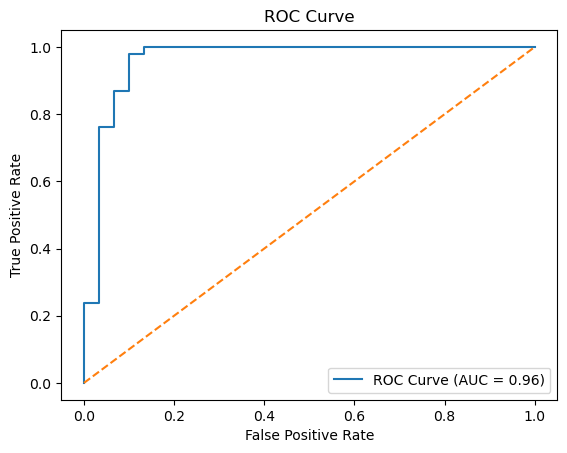

In [80]:
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label="Inactive")

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [81]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf_model.fit(X_train, y_train)

rf_pos_idx = list(rf_model.classes_).index("Active")
y_prob_rf = rf_model.predict_proba(X_test)[:, rf_pos_idx]
y_pred_rf = rf_model.predict(X_test)

print(f"RF accuracy:  {accuracy_score(y_test, y_pred_rf):.2f}")
print(f"RF precision: {precision_score(y_test, y_pred_rf, pos_label='Active'):.2f}")
print(f"RF recall:    {recall_score(y_test, y_pred_rf, pos_label='Active'):.2f}")
print(f"RF F1:        {f1_score(y_test, y_pred_rf, pos_label='Active'):.2f}")
print(f"RF AUC:       {roc_auc_score(y_test, y_prob_rf):.2f}")

RF accuracy:  0.92
RF precision: 0.93
RF recall:    0.87
RF F1:        0.90
RF AUC:       0.06


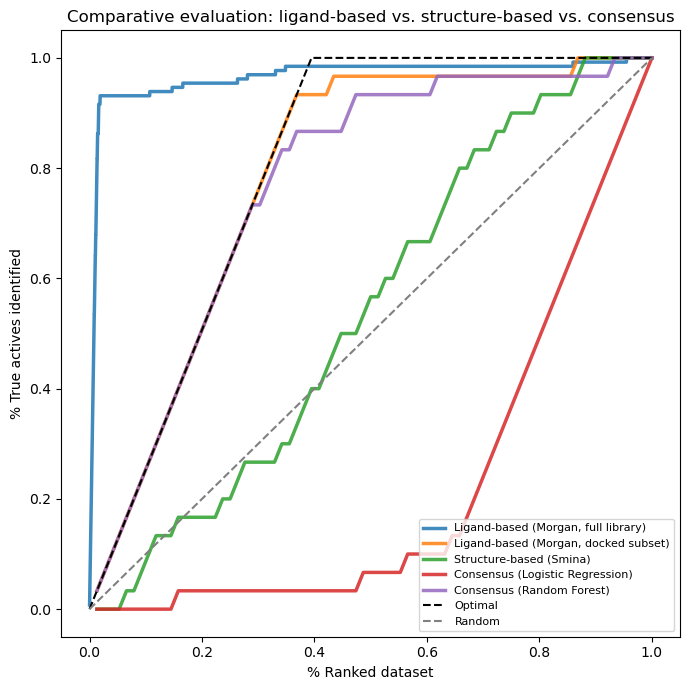

In [95]:
# --- Build a single dataframe carrying every method's score, restricted to the test set ---
eval_df = sampled_molecules.set_index("CHEMBL_ID").loc[X_test.index].copy()
eval_df["logreg_proba"] = y_prob      # from logistic regression, computed above
eval_df["rf_proba"]     = y_prob_rf   # from random forest, computed above

methods = {
    "Ligand-based (Morgan, full library)": (molecule_dataset, "tanimoto_morgan_similarity"),
    "Ligand-based (Morgan, docked subset)": (eval_df.reset_index(), "tanimoto_morgan_similarity"),
    "Structure-based (Smina)":              (eval_df.reset_index(), "smina_score"),   # note: more negative = better, see below
    "Consensus (Logistic Regression)":      (eval_df.reset_index(), "logreg_proba"),
    "Consensus (Random Forest)":            (eval_df.reset_index(), "rf_proba"),
}

fig, ax = plt.subplots(figsize=(7, 7))
for label, (df, col) in methods.items():
    df_ranked = df.copy()
    if col == "smina_score":
        df_ranked[col] = -df_ranked[col]   # flip sign: more negative Vina/Smina score = better, but get_enrichment_data ranks descending
    enrichment = get_enrichment_data(df_ranked, col, "Activity")
    ax.plot(enrichment["% ranked dataset"], enrichment["% true actives identified"],
             linewidth=2.5, alpha=0.85, label=label)

ratio_actives = sum(eval_df["Activity"] == "Active") / len(eval_df)
ax.plot([0, ratio_actives, 1], [0, 1, 1], color="black", linestyle="--", label="Optimal")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random")
ax.set_xlabel("% Ranked dataset"); ax.set_ylabel("% True actives identified")
ax.set_title("Comparative evaluation: ligand-based vs. structure-based vs. consensus")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("./comparative_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()

Random molecule test (CHEMBL Statin variant)

In [174]:
reference_data = {'Smiles': ['CC(C)C1=C(N=C(N1CC[C@H](C[C@H](CC(=O)O)O)O)C2=CC=C(C=C2)F)C(=O)NCC3=CC=CC=C3',
'CC[C@H](C)C(=O)O[C@H]1CCC=C2[C@H]1[C@H]([C@H](C=C2)C)CC[C@@H]3C[C@H](CC(=O)O3)O',
'CCC(C)(C)C(=O)O[C@H]1C[C@H](C=C2[C@H]1[C@H]([C@H](C=C2)C)CC[C@@H]3C[C@H](CC(=O)O3)O)C',
'CC(C)N1C2=CC=CC=C2C(=C1/C=C/[C@@H](C[C@@H](CC(=O)O)O)O)C3=CC=C(C=C3)F',
'CC(C)C1=C(C(=C(C(=N1)C(C)C)COC)C2=CC=C(C=C2)F)/C=C/[C@H](C[C@H](CC(=O)O)O)O',
'CC(C)C1=C(C(=C(N1CC[C@H](C[C@H](CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4'],
'CHEMBL_ID': ['CHEMBL488636', 'CHEMBL54440', 'CHEMBL1064', 'CHEMBL2220442', 'CHEMBL1477', 'CHEMBL1487']}
reference_df = pd.DataFrame(reference_data)

In [188]:
sampled_ids = list(sampled_molecules["CHEMBL_ID"])
reference_ids = list(reference_data['CHEMBL_ID'])

for ref_id in reference_ids:
    if ref_id in sampled_ids:
        print(ref_id)


'DECOY948' in X_test, 'DECOY948' in X_train

CHEMBL54440
CHEMBL2220442
CHEMBL1477
CHEMBL1487


(False, False)

In [191]:
import random
inactive_sampled = inactive_molecule_dataset.sample(1, random_state=12)
print(inactive_sampled["Smiles"])


1871    C=CCOc1ccccc1-c1ccc(C(=O)NC2(C3CCCCC3)C(=O)N(C...
Name: Smiles, dtype: object


In [193]:
inactive_molecule_dataset.loc[inactive_molecule_dataset["CHEMBL_ID"] == "DECOY948"]

,Smiles,CHEMBL_ID
1871,C=CCOc1ccccc1-c1ccc(C(=O)NC2(C3CCCCC3)C(=O)N(C...,DECOY948


In [194]:
test_active_molecule = {'Smiles': 'CC(C)C1=C(N=C(N1CC[C@H](C[C@H](CC(=O)O)O)O)C2=CC=C(C=C2)F)C(=O)NCC3=CC=CC=C3', 'CHEMBL_ID': 'CHEMBL488636'}

test_inactive_molecule = {'Smiles': 'C=CCOc1ccccc1-c1ccc(C(=O)NC2(C3CCCCC3)C(=O)N(C)c3ccc(C(=O)[O-])cc32)cc1C', 'CHEMBL_ID': 'DECOY948'}